# Lab 04-04 · Electric Potential, Capacitance and Dielectrics

Companion to chapter [04-04](../../chapters/04-04-potential-capacitance-and-dielectrics.md). Handout: [README.md](README.md). The ngspice netlist [charge_sharing.cir](charge_sharing.cir) simulates Example 04-04.7; run it with `python tools/run_spice.py 04-04` from the repository root.

Cells marked **🔮 Predict** ask for a prediction *before* running. Nothing here is random.

In [1]:
import math, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
sys.path.insert(0, str(Path.cwd().parents[3] / "tools"))
try:
    from plotstyle import use_style; use_style()
except ImportError:
    pass
eps0 = 8.8541878188e-12
ke = 1 / (4 * math.pi * eps0)
charges = [(1e-9, (0.0, 0.0)), (-1e-9, (0.04, 0.0))]      # +1 nC and -1 nC, 4 cm apart

def V(x, y):
    return sum(ke * q / np.hypot(x - x0, y - y0) for q, (x0, y0) in charges)

def E(x, y):
    Ex = Ey = 0.0
    for q, (x0, y0) in charges:
        r3 = np.hypot(x - x0, y - y0) ** 3
        Ex += ke * q * (x - x0) / r3; Ey += ke * q * (y - y0) / r3
    return np.array([Ex, Ey])

## Part 1 — Potential maps and the gradient

Map the potential of a ±1 nC pair 4 cm apart, draw its equipotentials, and recover the field by finite differences, $E_x \approx -[V(x + h) - V(x - h)]/2h$.

**🔮 Predict:** where is $V = 0$? Is the field zero there?

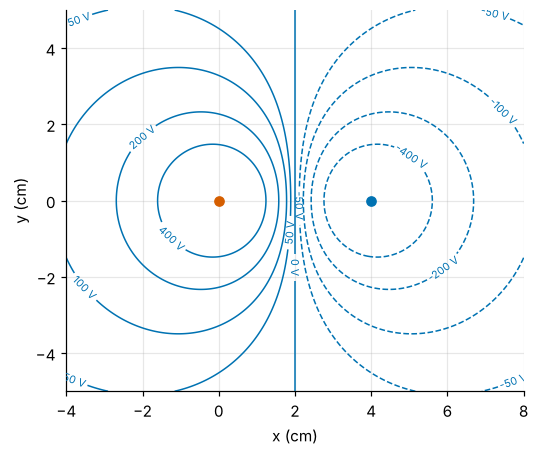

at (0.02, 0.03): V =     0.00 V; -grad V = [7669.84   -0.  ]; Coulomb E = [7669.84    0.  ] V/m
at (0.06, -0.01): V =  -254.18 V; -grad V = [-13681.4    7639.37]; Coulomb E = [-13681.4    7639.37] V/m


In [2]:
x = np.linspace(-0.04, 0.08, 400); y = np.linspace(-0.05, 0.05, 340)
X, Y = np.meshgrid(x, y)
Vg = V(X, Y)
fig, ax = plt.subplots(figsize=(6.5, 4.5))
cs = ax.contour(X * 100, Y * 100, Vg, levels=[-400, -200, -100, -50, 0, 50, 100, 200, 400], colors="C0", linewidths=1)
ax.clabel(cs, fontsize=7, fmt="%g V")
ax.plot([0], [0], "o", color="C1"); ax.plot([4], [0], "o", color="C0")
ax.set_aspect("equal"); ax.set_xlabel("x (cm)"); ax.set_ylabel("y (cm)"); plt.show()
h = 1e-6
for pt in ((0.02, 0.03), (0.06, -0.01)):
    fd = -np.array([(V(pt[0] + h, pt[1]) - V(pt[0] - h, pt[1])) / (2 * h), (V(pt[0], pt[1] + h) - V(pt[0], pt[1] - h)) / (2 * h)])
    print(f"at {pt}: V = {V(*pt):8.2f} V; -grad V = {fd.round(2)}; Coulomb E = {E(*pt).round(2)} V/m")

The $V = 0$ equipotential is the perpendicular bisector $x$ = 2 cm, yet the field there is about 7.7 kV/m: zero potential is not zero field. The finite-difference gradient matches the Coulomb field to the printed precision.

## Part 2 — Path independence

Integrate $\vec E\cdot d\vec l$ from A = (−2, 3) cm to B = (6, −1.5) cm along a straight line and along a wiggly path, and compare with $-(V_B - V_A)$.

**🔮 Predict:** how much do the two paths differ?

In [3]:
A, B = np.array([-0.02, 0.03]), np.array([0.06, -0.015])
def work_per_charge(path, n=200001):
    s = np.linspace(0, 1, n)
    P = np.array([path(si) for si in s])
    dP = np.gradient(P, s, axis=0)
    Ef = np.array([E(*p) for p in P])
    return np.trapezoid((Ef * dP).sum(axis=1), s)
straight = lambda s: A + s * (B - A)
perp = np.array([-(B - A)[1], (B - A)[0]]) / np.linalg.norm(B - A)
wiggly = lambda s: A + s * (B - A) + 0.015 * np.sin(5 * math.pi * s) * perp
w1, w2 = work_per_charge(straight), work_per_charge(wiggly)
print(f"straight path: {w1:.3f} V;  wiggly path: {w2:.3f} V;  -(V_B - V_A) = {-(V(*B) - V(*A)):.3f} V")

straight path: 329.473 V;  wiggly path: 329.473 V;  -(V_B - V_A) = 329.473 V


Both paths give the same 329.5 V: the field does the same work per unit charge whichever way you go, so $V_B - V_A = -329.5$ V is well defined.

## Part 3 — Capacitance from field energy

Integrate $u = \tfrac12\varepsilon_0E^2$ over space for a charged sphere (radius 5 cm) and for a coax ($a$ = 0.5 mm, $b$ = 2 mm, per meter), then set $U = Q^2/2C$.

**🔮 Predict:** the sphere's capacitance in pF.

In [4]:
Q, R = 1e-8, 0.05
U_s = quad(lambda r: 0.5 * eps0 * (ke * Q / r**2) ** 2 * 4 * math.pi * r**2, R, np.inf)[0]
print(f"sphere: U = {U_s:.4e} J -> C = {Q**2/(2*U_s)*1e12:.4f} pF (4 pi eps0 R = {4*math.pi*eps0*R*1e12:.4f} pF)")
lam, a, b = 2e-9, 5e-4, 2e-3
U_c = quad(lambda r: 0.5 * eps0 * (lam / (2 * math.pi * eps0 * r)) ** 2 * 2 * math.pi * r, a, b)[0]
print(f"coax: U = {U_c:.4e} J/m -> C = {lam**2/(2*U_c)*1e12:.4f} pF/m (2 pi eps0 / ln(b/a) = {2*math.pi*eps0/math.log(b/a)*1e12:.4f})")

sphere: U = 8.9876e-06 J -> C = 5.5633 pF (4 pi eps0 R = 5.5633 pF)
coax: U = 4.9838e-08 J/m -> C = 40.1304 pF/m (2 pi eps0 / ln(b/a) = 40.1304)


## Part 4 — Gate stacks

Vary the HfO₂ thickness on a 0.4 nm SiO₂ interface layer and track the EOT and the field in each layer at 0.7 V.

**🔮 Predict:** the EOT of 3 nm of HfO₂ on 0.4 nm of SiO₂.

EOT of 3 nm HfO2 on 0.4 nm SiO2: 0.868 nm
at 0.7 V: E(SiO2) = 8.06 MV/cm, E(HfO2) = 1.26 MV/cm


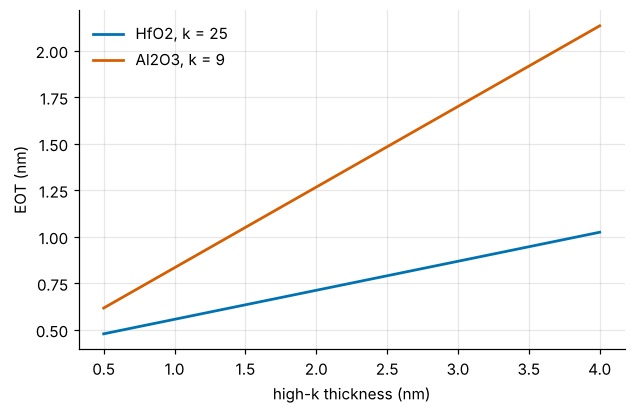

In [5]:
t_if = 0.4e-9
t_hk = np.linspace(0.5e-9, 4e-9, 100)
for k_hk, name in ((25, "HfO2, k = 25"), (9, "Al2O3, k = 9")):
    eot = t_if + t_hk * 3.9 / k_hk
    plt.plot(t_hk * 1e9, eot * 1e9, label=name)
print(f"EOT of 3 nm HfO2 on 0.4 nm SiO2: {(t_if + 3e-9*3.9/25)*1e9:.3f} nm")
D = 3.9 * eps0 / (t_if + 3e-9 * 3.9 / 25) * 0.7
print(f"at 0.7 V: E(SiO2) = {D/(3.9*eps0)/1e8:.2f} MV/cm, E(HfO2) = {D/(25*eps0)/1e8:.2f} MV/cm")
plt.xlabel("high-k thickness (nm)"); plt.ylabel("EOT (nm)"); plt.legend(); plt.show()

## Part 5 — A chuck's sensitivity to a gap

**🔮 Predict:** the clamping force of Example 04-04.8's chuck with a 5 µm gap.

F(0) = 36.94 N; F(5 um) = 31.58 N


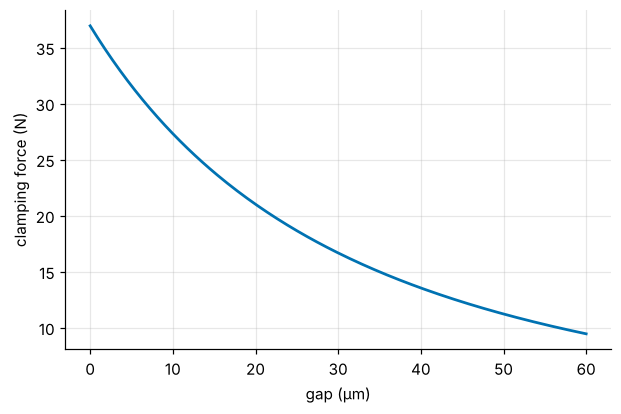

In [6]:
S, l, er, Vc = math.pi * 0.1**2, 0.54e-3, 8.8, 1000.0
g = np.linspace(0, 60e-6, 200)
F = eps0 * S * Vc**2 / (2 * (g + l / er) ** 2)
print(f"F(0) = {F[0]:.2f} N; F(5 um) = {eps0*S*Vc**2/(2*(5e-6 + l/er)**2):.2f} N")
plt.plot(g * 1e6, F); plt.xlabel("gap (µm)"); plt.ylabel("clamping force (N)"); plt.show()

A 5 µm gap costs about 15% of the force, and a gap equal to $l/\varepsilon_r$ (61 µm) costs three quarters.

## Your turn

1. In Part 2, make the wiggly path loop once around the +1 nC charge before reaching B. Does the answer change? Why not?
2. In Part 3, compute what fraction of the coax's field energy lies within 0.1 mm of the inner conductor.